In [3]:
import pandas as pd

import numpy as np

from pathlib import Path

In [4]:
DATA_DIR = Path("../data/raw")

print("Chemin du dossier :", DATA_DIR.resolve())
DATA_FILE = DATA_DIR/"student_mental_health.csv"

df = pd.read_csv(DATA_FILE)

Chemin du dossier : C:\Users\ajbba\Desktop\YOUCODE-IA\Mental_Health_Risk_Prediction\data\raw


In [5]:
#partie de preprocessing 
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer


In [6]:
TARGET_COLUMN = "Mental_Health_Risk"
y = df[TARGET_COLUMN]

In [7]:
X=df.drop(columns=[TARGET_COLUMN])
print("Dimensions des variables explicatives :", X.shape)

print("Dimensions de la variable cible :", y.shape)

Dimensions des variables explicatives : (2000, 16)
Dimensions de la variable cible : (2000,)


In [8]:
X_train, X_test, y_train, y_test= train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("dimension de X_train",X_train.shape)
print("dimension de X_test",X_test.shape)
print("dimension de y_train",y_train.shape)
print("dimension de y_test",y_test.shape)

dimension de X_train (1600, 16)
dimension de X_test (400, 16)
dimension de y_train (1600,)
dimension de y_test (400,)


In [9]:
print("la taille initial de df est:",len(df))
print("la taille initial de train est:",len(X_train))
print("la taille initial de test est:",len(X_test))
print("le pourcentage de train data est :",((len(X_train)/len(df))*100))
print("le pourcentage de test data est :",((len(X_test)/len(df))*100))


la taille initial de df est: 2000
la taille initial de train est: 1600
la taille initial de test est: 400
le pourcentage de train data est : 80.0
le pourcentage de test data est : 20.0


In [10]:
missing_train=X_train.isnull().sum()
missing_train=missing_train[missing_train>0]
display(missing_train)

Sleep_Hours           54
GPA                   36
Social_Media_Hours    48
Financial_Stress      76
Family_Support        36
Attendance_Rate       39
Diet_Quality          55
dtype: int64

In [11]:
missing_test=X_test.isnull().sum()
missing_test=missing_test[missing_test>0]
display(missing_test)

Sleep_Hours            8
GPA                    2
Social_Media_Hours    10
Financial_Stress      15
Family_Support        18
Attendance_Rate        8
Diet_Quality          14
dtype: int64

In [12]:
#separer categorical et numeric
numeric_features=X_train.select_dtypes(
    include=np.number
).columns.tolist()
categorical_features=X_train.select_dtypes(
    include=["object","bool","category"]
).columns.tolist()

print("les variables numeriques",numeric_features)
print("les variables categoricals",categorical_features)

les variables numeriques ['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']
les variables categoricals ['Student_ID', 'Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History']


C:\Users\ajbba\AppData\Local\Temp\ipykernel_11712\1339826814.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features=X_train.select_dtypes(


In [13]:
numeric_imputer = SimpleImputer(strategy="median")

X_train[numeric_features] = numeric_imputer.fit_transform(
    X_train[numeric_features]
)

X_test[numeric_features] = numeric_imputer.transform(
    X_test[numeric_features]
)

In [14]:
categorical_imputer = SimpleImputer(strategy="most_frequent")

X_train[categorical_features] = categorical_imputer.fit_transform(
    X_train[categorical_features]
)

X_test[categorical_features] = categorical_imputer.transform(
    X_test[categorical_features]
)

In [15]:
print("Missing Values dans Training :")
print(X_train.isnull().sum().sum())

print("\nMissing Values dans Testing :")
print(X_test.isnull().sum().sum())

Missing Values dans Training :
0

Missing Values dans Testing :
0


In [16]:
iqr_limits = {}

for column in numeric_features:

    Q1 = X_train[column].quantile(0.25)

    Q3 = X_train[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR

    upper_bound = Q3 + 1.5 * IQR

    iqr_limits[column] = {
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound
    }

iqr_limits_df = pd.DataFrame(iqr_limits).T

display(iqr_limits_df)

,Q1,Q3,IQR,Lower Bound,Upper Bound
Age,20.00,23.00,3.00,15.50,27.50
Year_of_Study,1.00,4.00,3.00,-3.50,8.50
Sleep_Hours,6.00,7.50,1.50,3.75,9.75
Study_Hours_Per_Week,16.00,24.00,8.00,4.00,36.00
GPA,2.33,2.79,0.46,1.64,3.48
Social_Media_Hours,5.30,6.70,1.40,3.20,8.80
Screen_Time_Hours,7.40,9.70,2.30,3.95,13.15
Financial_Stress,4.60,7.40,2.80,0.40,11.60
Family_Support,5.20,8.00,2.80,1.00,12.20
Attendance_Rate,80.30,89.90,9.60,65.90,104.30


In [17]:
outliers_count = {}

for column in numeric_features:

    lower_bound = iqr_limits[column]["Lower Bound"]

    upper_bound = iqr_limits[column]["Upper Bound"]

    outliers = X_train[
        (X_train[column] < lower_bound) |
        (X_train[column] > upper_bound)
    ]

    outliers_count[column] = len(outliers)

outliers_count_df = pd.DataFrame(
    list(outliers_count.items()),
    columns=["Variable", "Nombre_Outliers"]
)

display(outliers_count_df)

,Variable,Nombre_Outliers
0,Age,2
1,Year_of_Study,0
2,Sleep_Hours,9
3,Study_Hours_Per_Week,7
4,GPA,8
5,Social_Media_Hours,16
6,Screen_Time_Hours,7
7,Financial_Stress,0
8,Family_Support,0
9,Attendance_Rate,10


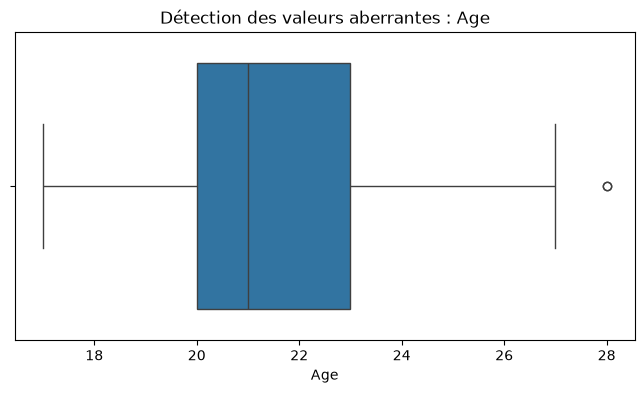

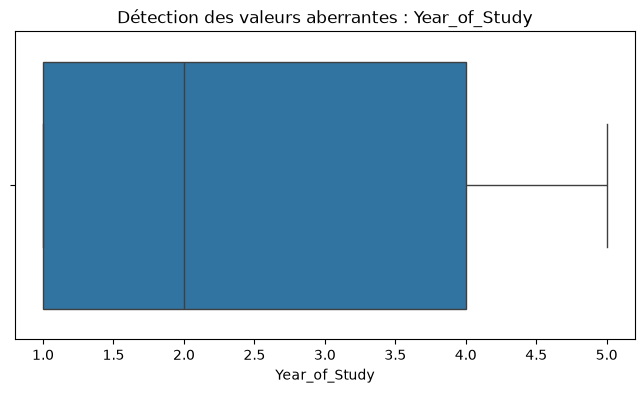

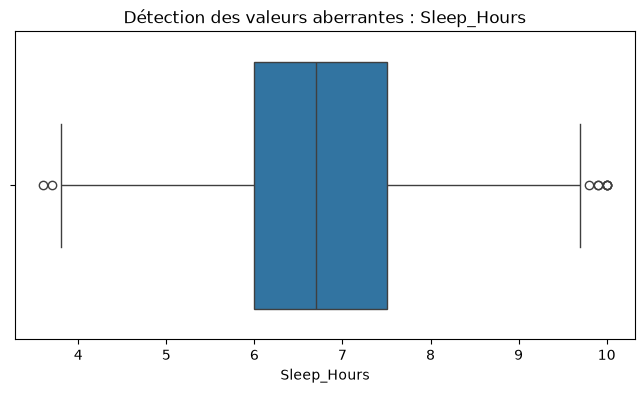

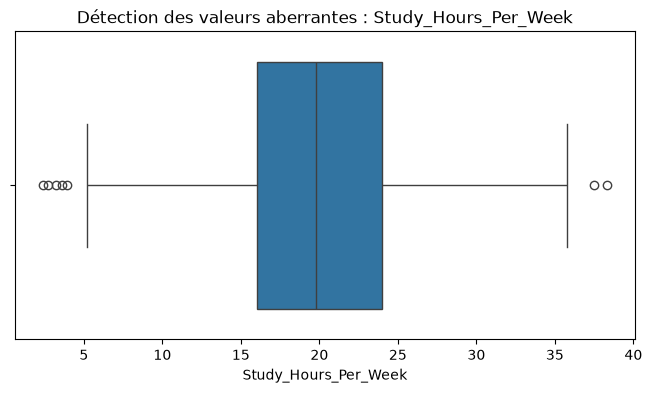

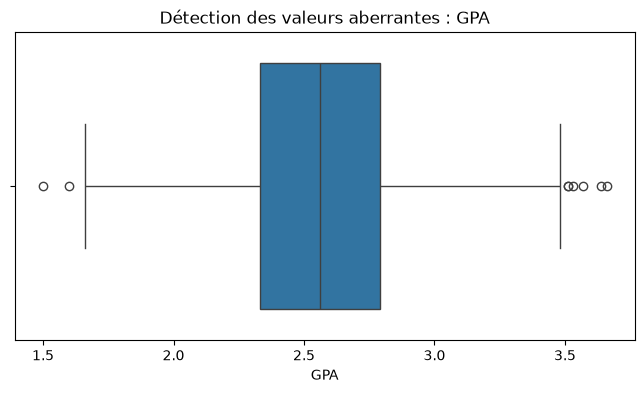

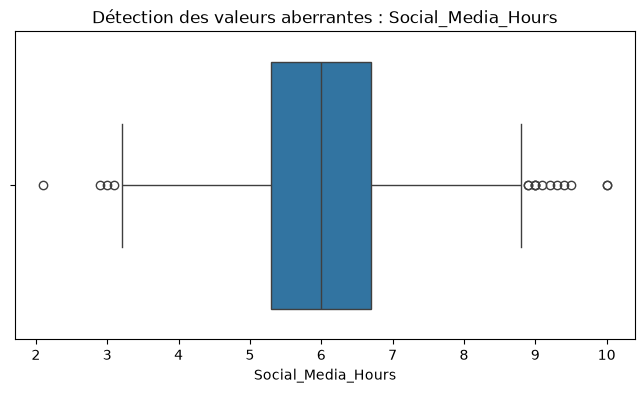

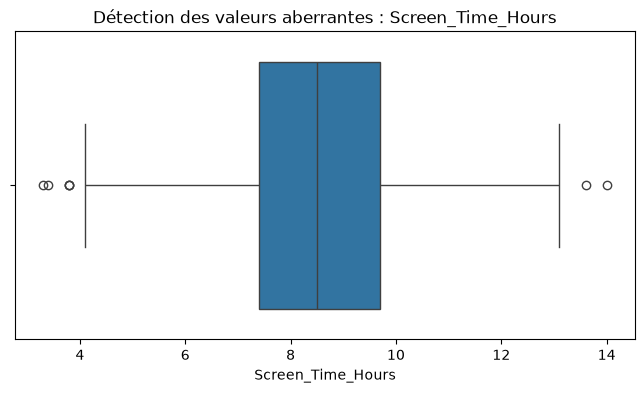

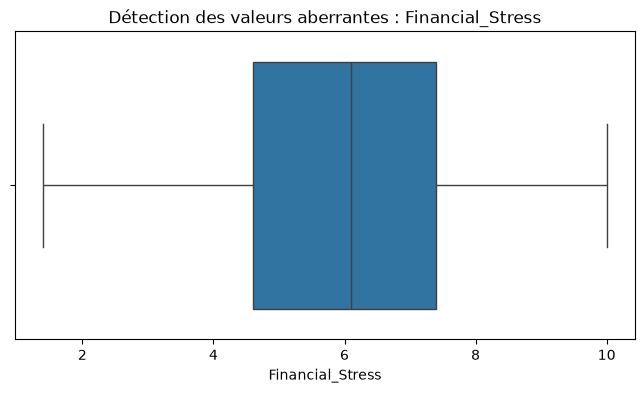

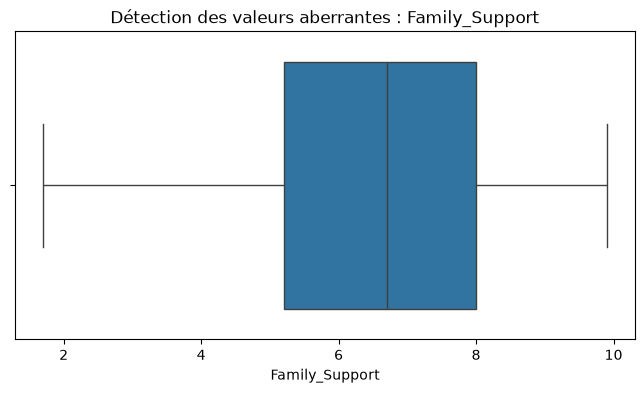

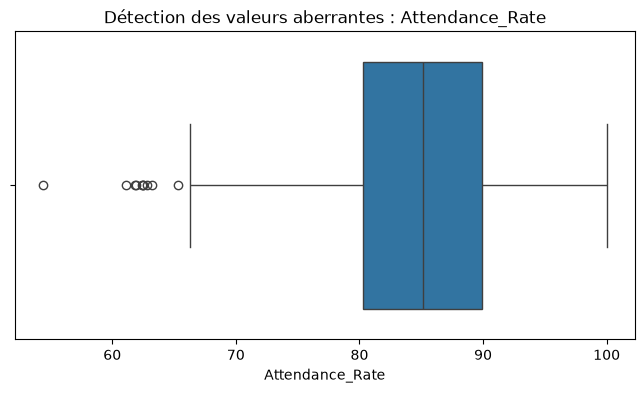

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

for column in numeric_features:

    plt.figure(figsize=(8, 4))

    sns.boxplot(x=X_train[column])

    plt.title(f"Détection des valeurs aberrantes : {column}")

    plt.xlabel(column)

    plt.show()

In [19]:
X_train_iqr = X_train.copy()
X_test_iqr = X_test.copy()

for column in numeric_features:

    lower_bound = iqr_limits[column]["Lower Bound"]

    upper_bound = iqr_limits[column]["Upper Bound"]

    X_train_iqr[column] = X_train_iqr[column].clip(
        lower=lower_bound,
        upper=upper_bound
    )

    X_test_iqr[column] = X_test_iqr[column].clip(
        lower=lower_bound,
        upper=upper_bound
    )

In [20]:
from scipy.stats import zscore

z_scores = pd.DataFrame(
    zscore(X_train[numeric_features], nan_policy="omit"),
    columns=numeric_features,
    index=X_train.index
)

display(z_scores.head())

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
726,-0.063706,-0.471636,-1.404182,-0.238603,0.074214,0.148597,1.098992,0.713748,0.643008,-1.244652
1384,0.875744,-1.232340,-1.676036,-1.330997,-0.976093,0.327697,0.194658,-0.842691,0.368687,-0.465696
1579,-1.003157,-0.471636,0.408177,-0.516037,-1.034443,-0.299153,-0.830254,-0.305988,0.752736,0.772288
1098,0.875744,-1.232340,1.404975,-0.082547,0.891120,0.775447,1.098992,0.821088,-0.948052,-0.215317
582,0.406019,0.289067,0.408177,0.663055,-0.275888,-0.388703,-0.347943,0.660077,0.697872,-1.453301


In [21]:
zscore_outliers = z_scores.abs() > 3

outliers_per_column = zscore_outliers.sum()

print("Nombre d'Outliers par variable :")

display(outliers_per_column)

Nombre d'Outliers par variable :


Age                     2
Year_of_Study           0
Sleep_Hours             0
Study_Hours_Per_Week    3
GPA                     3
Social_Media_Hours      5
Screen_Time_Hours       4
Financial_Stress        0
Family_Support          0
Attendance_Rate         9
dtype: int64

In [22]:
rows_with_outliers = zscore_outliers.any(axis=1)

print(
    "Nombre de lignes contenant au moins un Outlier :",
    rows_with_outliers.sum()
)

Nombre de lignes contenant au moins un Outlier : 24


In [23]:
print("Variables catégorielles :")
print(categorical_features)

print("\nNombre de variables catégorielles :")
print(len(categorical_features))

Variables catégorielles :
['Student_ID', 'Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History']

Nombre de variables catégorielles :
6


In [24]:
for column in categorical_features:

    print(f"\nColonne : {column}")

    print(df[column].unique())

    print("Nombre de catégories :", df[column].nunique())


Colonne : Student_ID
<StringArray>
['STU0001', 'STU0002', 'STU0003', 'STU0004', 'STU0005', 'STU0006', 'STU0007',
 'STU0008', 'STU0009', 'STU0010',
 ...
 'STU1991', 'STU1992', 'STU1993', 'STU1994', 'STU1995', 'STU1996', 'STU1997',
 'STU1998', 'STU1999', 'STU2000']
Length: 2000, dtype: str
Nombre de catégories : 2000

Colonne : Gender
<StringArray>
['Male', 'Female', 'Non-binary']
Length: 3, dtype: str
Nombre de catégories : 3

Colonne : Physical_Activity
<StringArray>
['Moderate', 'Low', 'High']
Length: 3, dtype: str
Nombre de catégories : 3

Colonne : Part_Time_Job
<StringArray>
['No', 'Yes']
Length: 2, dtype: str
Nombre de catégories : 2

Colonne : Diet_Quality
<StringArray>
['Poor', 'Average', nan, 'Good']
Length: 4, dtype: str
Nombre de catégories : 3

Colonne : Previous_Mental_Health_History
<StringArray>
['No', 'Yes']
Length: 2, dtype: str
Nombre de catégories : 2


In [25]:
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder

In [26]:
ordinal_features = [
    "Diet_Quality",
    "Physical_Activity"
]

print("Variables ordinales :")
print(ordinal_features)

Variables ordinales :
['Diet_Quality', 'Physical_Activity']


In [27]:
for column in ordinal_features:

    print(f"\nColonne : {column}")

    print("Training :", X_train[column].unique())

    print("Testing :", X_test[column].unique())


Colonne : Diet_Quality
Training : <StringArray>
['Average', 'Poor', 'Good']
Length: 3, dtype: str
Testing : <StringArray>
['Good', 'Average', 'Poor']
Length: 3, dtype: str

Colonne : Physical_Activity
Training : <StringArray>
['Moderate', 'High', 'Low']
Length: 3, dtype: str
Testing : <StringArray>
['Low', 'Moderate', 'High']
Length: 3, dtype: str


In [28]:
ordinal_encoder = OrdinalEncoder(
    categories=[
        ["Poor", "Average", "Good"],
        ["Low", "Moderate", "High"]
    ],
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

In [29]:
X_train[ordinal_features] = ordinal_encoder.fit_transform(
    X_train[ordinal_features]
)

X_test[ordinal_features] = ordinal_encoder.transform(
    X_test[ordinal_features]
)

In [30]:
categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

nominal_features = [
    column for column in categorical_features
    if column not in ordinal_features
]

print("Variables nominales :")
print(nominal_features)

Variables nominales :
['Student_ID', 'Gender', 'Part_Time_Job', 'Previous_Mental_Health_History']


C:\Users\ajbba\AppData\Local\Temp\ipykernel_11712\2140330826.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [31]:
onehot_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

In [32]:
if len(nominal_features) > 0:

    encoded_train = onehot_encoder.fit_transform(
        X_train[nominal_features]
    )

    encoded_test = onehot_encoder.transform(
        X_test[nominal_features]
    )

    encoded_columns = onehot_encoder.get_feature_names_out(
        nominal_features
    )

    encoded_train = pd.DataFrame(
        encoded_train,
        columns=encoded_columns,
        index=X_train.index
    )

    encoded_test = pd.DataFrame(
        encoded_test,
        columns=encoded_columns,
        index=X_test.index
    )

In [33]:
if len(nominal_features) > 0:


    X_train = X_train.drop(columns=nominal_features)

    X_test = X_test.drop(columns=nominal_features)

    X_train = pd.concat(
        [X_train, encoded_train],
        axis=1
    )

    X_test = pd.concat(
        [X_test, encoded_test],
        axis=1
    )

In [34]:
print("Dimensions de X_train :", X_train.shape)

print("Dimensions de X_test :", X_test.shape)

print("\nTypes des variables dans Training :")

print(X_train.dtypes)

print("\nAperçu de Training :")

display(X_train.head())

print("\nAperçu de Testing :")

display(X_test.head())

Dimensions de X_train : (1600, 1619)
Dimensions de X_test : (400, 1619)

Types des variables dans Training :
Age                                   float64
Year_of_Study                         float64
Sleep_Hours                           float64
Study_Hours_Per_Week                  float64
GPA                                   float64
                                       ...   
Gender_Non-binary                     float64
Part_Time_Job_No                      float64
Part_Time_Job_Yes                     float64
Previous_Mental_Health_History_No     float64
Previous_Mental_Health_History_Yes    float64
Length: 1619, dtype: object

Aperçu de Training :


,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,...,Student_ID_STU1997,Student_ID_STU1998,Student_ID_STU2000,Gender_Female,Gender_Male,Gender_Non-binary,Part_Time_Job_No,Part_Time_Job_Yes,Previous_Mental_Health_History_No,Previous_Mental_Health_History_Yes
726,21.0,2.0,5.2,18.6,2.59,6.2,10.4,1.0,7.3,7.7,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
1384,23.0,1.0,4.9,12.3,2.23,6.4,8.9,2.0,4.4,7.2,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
1579,19.0,2.0,7.2,17.0,2.21,5.7,7.2,1.0,5.4,7.9,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
1098,23.0,1.0,8.3,19.5,2.87,6.9,10.4,1.0,7.5,4.8,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
582,22.0,3.0,7.2,23.8,2.47,5.6,8.0,2.0,7.2,7.8,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0



Aperçu de Testing :


,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,...,Student_ID_STU1997,Student_ID_STU1998,Student_ID_STU2000,Gender_Female,Gender_Male,Gender_Non-binary,Part_Time_Job_No,Part_Time_Job_Yes,Previous_Mental_Health_History_No,Previous_Mental_Health_History_Yes
397,24.0,5.0,5.2,28.1,3.31,5.7,7.7,0.0,6.4,6.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
22,21.0,3.0,7.0,22.3,2.63,2.4,5.2,1.0,6.9,7.2,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
720,22.0,4.0,5.9,21.7,2.23,6.1,9.0,1.0,3.1,9.4,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0
1624,25.0,1.0,6.9,19.7,2.35,6.4,8.8,0.0,6.8,7.2,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
1388,21.0,3.0,5.1,21.3,2.60,5.6,8.7,0.0,2.4,1.9,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0


In [35]:
print("Variables non numériques dans Training :")

print(
    X_train.select_dtypes(
        exclude=np.number
    ).columns.tolist()
)

print("\nVariables non numériques dans Testing :")

print(
    X_test.select_dtypes(
        exclude=np.number
    ).columns.tolist()
)

Variables non numériques dans Training :
[]

Variables non numériques dans Testing :
[]


In [36]:
# Distribution des classes dans data de train
clas_distribution=y_train.value_counts()
print("la distribution des classes est :",clas_distribution)
class_pourcentage=y_train.value_counts(normalize=True)*100
print("le pourcentage de chaque classe est: ",class_pourcentage)

la distribution des classes est : Mental_Health_Risk
High      544
Medium    528
Low       528
Name: count, dtype: int64
le pourcentage de chaque classe est:  Mental_Health_Risk
High      34.0
Medium    33.0
Low       33.0
Name: proportion, dtype: float64


In [37]:
#standarisation et normalisation
from sklearn.preprocessing import StandardScaler

In [38]:
numeric_features_to_scale=[
    column
    for column in X_train.select_dtypes(include=np.number).columns
    if X_train[column].nunique() > 2
    if column not in ordinal_features
]

print ("les variables numeriques a standarises sans :", numeric_features_to_scale)

les variables numeriques a standarises sans : ['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']


In [39]:
#creation d'objet standardscaler 
scaler=StandardScaler()

In [40]:
#standariser les variables numeriques de train
X_train[numeric_features_to_scale]=scaler.fit_transform(
    X_train[numeric_features_to_scale]
)

In [41]:
#standariser les variables numeriques de test
X_test[numeric_features_to_scale]=scaler.transform(
    X_test[numeric_features_to_scale]
)

In [42]:
# Vérifier les statistiques après standardisation

print("Moyenne des variables standarisees :")
print(X_train[numeric_features_to_scale].mean().round(2))

print("Ecart-type des variables standarisees :")
print(X_train[numeric_features_to_scale].std().round(2))

Moyenne des variables standarisees :
Age                    -0.0
Year_of_Study          -0.0
Sleep_Hours             0.0
Study_Hours_Per_Week    0.0
GPA                    -0.0
Social_Media_Hours     -0.0
Screen_Time_Hours      -0.0
Financial_Stress       -0.0
Family_Support          0.0
Attendance_Rate        -0.0
dtype: float64
Ecart-type des variables standarisees :
Age                     1.0
Year_of_Study           1.0
Sleep_Hours             1.0
Study_Hours_Per_Week    1.0
GPA                     1.0
Social_Media_Hours      1.0
Screen_Time_Hours       1.0
Financial_Stress        1.0
Family_Support          1.0
Attendance_Rate         1.0
dtype: float64


In [43]:
print("Dimensions de X_train :", X_train.shape)
print("Dimensions de X_test :", X_test.shape)

print(" les  donnees apres standardisation :")
display(X_train.head())

Dimensions de X_train : (1600, 1619)
Dimensions de X_test : (400, 1619)
 les  donnees apres standardisation :


,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,...,Student_ID_STU1997,Student_ID_STU1998,Student_ID_STU2000,Gender_Female,Gender_Male,Gender_Non-binary,Part_Time_Job_No,Part_Time_Job_Yes,Previous_Mental_Health_History_No,Previous_Mental_Health_History_Yes
726,-0.063706,-0.471636,-1.404182,-0.238603,0.074214,0.148597,1.098992,1.0,0.713748,0.643008,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
1384,0.875744,-1.232340,-1.676036,-1.330997,-0.976093,0.327697,0.194658,2.0,-0.842691,0.368687,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
1579,-1.003157,-0.471636,0.408177,-0.516037,-1.034443,-0.299153,-0.830254,1.0,-0.305988,0.752736,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
1098,0.875744,-1.232340,1.404975,-0.082547,0.891120,0.775447,1.098992,1.0,0.821088,-0.948052,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
582,0.406019,0.289067,0.408177,0.663055,-0.275888,-0.388703,-0.347943,2.0,0.660077,0.697872,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0


In [44]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.impute import SimpleImputer

from sklearn.preprocessing import (
    StandardScaler,
    OrdinalEncoder,
    OneHotEncoder
)

In [45]:
X = df.drop(columns=[TARGET_COLUMN]).copy()

y = df[TARGET_COLUMN].copy()

In [46]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [49]:
ordinal_features = [
    "Diet_Quality",
    "Physical_Activity"
]
numeric_features = [
    column
    for column in X_train.select_dtypes(include=np.number).columns
    if column not in ordinal_features
]
nominal_features = [
    column
    for column in X_train.select_dtypes(
        include=["object", "category", "bool"]
    ).columns
    if column not in ordinal_features
]

C:\Users\ajbba\AppData\Local\Temp\ipykernel_11712\1857344206.py:12: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in X_train.select_dtypes(


In [50]:
print("Variables numériques :")
print(numeric_features)

print("\nVariables ordinales :")
print(ordinal_features)

print("\nVariables nominales :")
print(nominal_features)

Variables numériques :
['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']

Variables ordinales :
['Diet_Quality', 'Physical_Activity']

Variables nominales :
['Student_ID', 'Gender', 'Part_Time_Job', 'Previous_Mental_Health_History']


In [51]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [53]:
ordinal_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        categories=[
            ["Poor", "Average", "Good"],
            ["Low", "Moderate", "High"]
        ]
    ))
])

In [54]:
nominal_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [55]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("ord", ordinal_pipeline, ordinal_features),
        ("nom", nominal_pipeline, nominal_features)
    ],
    remainder="drop"
)

In [56]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

In [57]:
print("Shape de X_train avant preprocessing :", X_train.shape)

print("Shape de X_train après preprocessing :", X_train_processed.shape)

print("Shape de X_test avant preprocessing :", X_test.shape)

print("Shape de X_test après preprocessing :", X_test_processed.shape)

Shape de X_train avant preprocessing : (1600, 16)
Shape de X_train après preprocessing : (1600, 1619)
Shape de X_test avant preprocessing : (400, 16)
Shape de X_test après preprocessing : (400, 1619)
